<a href="https://colab.research.google.com/github/Stivoni/01-pet-fostering-cta/blob/main/cai4002_hw2_two_numbers_three_keys.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CAI 4002 — Homework 2
## Two numbers, three keys

**Module 2 · Informed Search** · **Due: Sunday, October 11** (time and point
values on Canvas)

---

In Homework 1 you wrote one search driver and three containers, and the
container decided the algorithm: a queue gave breadth-first search, a stack gave
depth-first search, and a priority queue ordered by the cost paid so far, `g`,
gave uniform-cost search. None of those agents ever looked at where the exit
was.

In lecture we added a second number to every state: `h`, an *estimate* of the
cost still to come. The claim of the module is short:

> *The pop key decides the guarantee. Lowest `g`: the cheapest route, in every
> direction. Lowest `h`: fast, no guarantee. Lowest `g + h`: the cheapest route,
> steered toward the goal — on one condition: `h` never overestimates.*

This assignment does two things with that claim.

**Part A — same maze, a sense of direction.** On one fixed maze you give the
driver the second number and two new containers. The same driver then runs
uniform-cost search, greedy best-first search and A*, and you measure what each
key gains and what it loses.

**Part B — same driver, four heuristics.** The agent stops changing. Only `h`
changes: nothing, a straight line, an exaggeration, and the truth itself. For
each one you predict, run, and say what the guarantee did.

## How this is graded, and what to do about AI

**Your maze is your own.** Section 0 builds a maze from your Panther ID.
Everyone's numbers are different, so the numbers in your report have to come
from your own run.

**Before you submit: `Runtime → Restart session and run all`** (Colab) or
`Kernel → Restart Kernel and Run All Cells` (Jupyter). Your notebook is
re-run from a clean kernel when it is graded. Cells that only work because
you ran them out of order score zero.

**Submit two files:** the `.ipynb` *and* a PDF export of it.

**Using an AI assistant.** Ask it to *explain* — what a cell does, why your
number differs from the lecture's, what an error message means. Do not ask it
to write the cells for you. Two reasons, both practical:

1. The exam asks you to reason about a heuristic you have not seen, under time
   pressure and without an assistant. This assignment is the only practice you
   get.
2. Before the exam you will reread this notebook. It will contain either your
   own reasoning, in your own words, or text you never understood.

## What you actually have to do

**Three code cells. Two tables. Sixteen short written answers and three
predictions.** Everything in Section 0 runs for you — you never edit it.

| where | what you do |
|---|---|
| 0.1 | type your Panther ID |
| A1 | run the given agent · 1 answer |
| **A2** | ★ **write `manhattan()`** — the heuristic, three lines · 2 answers |
| **A3** | ★ **write `search()`** — the driver, with a new push rule |
| **A4** | ★ **write two container classes** — two short methods each |
| A5 | nothing to write; your code has to make it print `all five OK` |
| A6 | run · fill the comparison table · 3 answers |
| B0 | fill the heuristic table · one row per heuristic |
| B1 | predict · run · 2 answers |
| B2 | predict · run · 1 answer |
| B3 | predict · run · 2 answers |
| B4 | run · 2 answers |
| B5 | no code at all · 3 answers |

★ marks the only three cells where you write code — around forty lines in
total. A5 then tells you whether they are right, so you never have to guess.

**A prediction is worth the same whether it turns out right or wrong.** Write
what you actually expect; being wrong and seeing why is the point.

**Five words used throughout.**
* The *driver* is the loop the lecture calls the search framework:
  pop → goal test → expand → push.
* The *key* is the number a priority queue sorts by; the smallest key pops first.
* A square is *expanded* when it is popped and its neighbours are generated.
  The counts in this notebook are expansions: a square counts once, even if two
  entries for it were pushed.
* One admissible heuristic is *sharper* than another when it is closer to the
  true cost — larger, while still never above the truth.
* The *peak frontier* is the largest number of entries the frontier held at
  once during a run.

**Finding your way around.** This notebook is long. Open the table of contents
(the ☰ icon at the top left) and jump between sections instead of scrolling.

## Section 0 — Setup

Run the next cell once. Do not edit it, and do not delete it.

In [45]:
# @title Setup — run this cell, then leave it alone  { display-mode: "form" }
# =============================================================================
#  CAI 4002 · Homework 2 · provided code.  DO NOT EDIT THIS CELL.
#
#  Everything the assignment gives you lives here: the maze world, the search
#  driver you wrote in Homework 1 (now given), the uniform-cost container, the
#  drawing code, and the bookkeeping that counts pops and frontier size.
#
#  The CONVENTIONS are fixed here, and they are the ones the lecture used:
#      * neighbours are always generated in the order  U, R, D, L
#      * the goal test happens when a state is POPPED, not when it is pushed
#      * a priority queue breaks ties by insertion order (oldest first)
#      * an entry that is out of date (its state was already expanded at a
#        smaller cost) is skipped when it pops; a skip is not an expansion
#  Change any of these and your numbers will stop matching the lecture's.
# =============================================================================
import heapq, itertools, math, random, time


# ----------------------------------------------------------------- the maze --
# The 9x9 arena maze from lecture.  '#' = wall, '.' = free, start = (1,1) and
# exit = (7,7).  Coordinates are (row, column), matching maze[r][c].
LECTURE_MAZE = [
    "#########",
    "#.......#",
    "#.#.#.#.#",
    "#.#.#...#",
    "#.#####.#",
    "#...#...#",
    "###.#.#.#",
    "#...#..g#",
    "#########",
]
LECTURE_MUD = {(2, 7): 6, (6, 7): 6}   # entering these squares costs 6, not 1

MOVES = (("U", -1, 0), ("R", 0, 1), ("D", 1, 0), ("L", 0, -1))   # the order


# ------------------------------------------------------------------- world ---
class MazeWorld:
    """The maze world.  An agent talks to it through exactly three methods:
        initial_state()      where it starts
        is_goal(s)           is this the exit?
        neighbours(s)        [(action, next_state, step_cost), ...] in U,R,D,L
    and it may read `world.exit` — the goal's coordinates.  That is the one
    piece of knowledge the blind agents of Homework 1 never used.
    """
    name = "the maze"

    def __init__(self, grid=None, mud=None, start=(1, 1), exit=(7, 7)):
        self.grid = list(grid or LECTURE_MAZE)
        self.mud = dict(LECTURE_MUD if mud is None else mud)
        self.start, self.exit = start, exit

    def initial_state(self):
        return self.start

    def is_goal(self, s):
        return s == self.exit

    def neighbours(self, s):
        out = []
        for (a, dr, dc) in MOVES:
            v = (s[0] + dr, s[1] + dc)
            if self.grid[v[0]][v[1]] == "#":
                continue
            out.append((a, v, self.mud.get(v, 1)))
        return out

    def unit(self):
        """The same maze with every step costing 1 (no mud)."""
        return MazeWorld(grid=self.grid, mud={}, start=self.start, exit=self.exit)

    def free_cells(self):
        return [(r, c) for r, row in enumerate(self.grid)
                for c, ch in enumerate(row) if ch != "#"]


# ---------------------------------------------------------------- bookkeeping --
class Node:
    """One entry in the search tree: a state, how we got there, what it cost
    so far (g), and the estimate of what is still to come (h)."""
    __slots__ = ("state", "parent", "action", "g", "h")

    def __init__(self, state, parent=None, action=None, g=0, h=0):
        self.state, self.parent, self.action, self.g, self.h = state, parent, action, g, h

    @property
    def f(self):
        return self.g + self.h

    def path(self):
        node, out = self, []
        while node is not None:
            out.append(node)
            node = node.parent
        out.reverse()
        return out

    def plan(self):
        return [n.action for n in self.path() if n.action is not None]

    def states(self):
        return [n.state for n in self.path()]

    def __repr__(self):
        return f"Node({self.state}, g={self.g}, h={self.h})"


class Frontier:
    """Base class for the containers.  Counts pops and peak size for you.

    A subclass supplies exactly two methods:
        _put(node)   put a node in
        _take()      take the next node out  <- THIS is what makes the algorithm
    """
    def __init__(self):
        self._items, self.pops, self.peak, self._seq = [], 0, 0, itertools.count()
        self._popped, self.order = set(), []      # states expanded, and in what order
        self.g_at = {}                             # the g each state was expanded at

    def push(self, node):
        self._put(node)
        self.peak = max(self.peak, len(self))
        return node

    def pop(self):
        self.pops += 1
        node = self._take()
        if node.state not in self._popped:
            self._popped.add(node.state)
            self.order.append(node.state)
            self.g_at[node.state] = node.g
        return node

    @property
    def expansions(self):
        """Distinct states popped = states expanded.  This is the number the
        lecture reports.  `pops` counts every pop, including an out-of-date entry
        that the driver skips; `expansions` does not."""
        return len(self._popped)

    @property
    def expanded(self):
        """The set of states expanded so far."""
        return set(self._popped)

    def is_empty(self):
        return len(self) == 0

    def __len__(self):
        return len(self._items)

    def _put(self, node):
        raise NotImplementedError("you write this")

    def _take(self):
        raise NotImplementedError("you write this")


class PriorityByG(Frontier):
    """Uniform-cost search: the node with the smallest g comes out next.
    (This is the PriorityByCost container from Homework 1, given to you.)"""
    def _put(self, node): heapq.heappush(self._items, (node.g, next(self._seq), node))
    def _take(self): return heapq.heappop(self._items)[2]


# ------------------------------------------------ the Homework 1 driver ------
def search_blind(world, frontier):
    """The search driver from Homework 1:  pop -> goal test -> expand -> push.
    A state is pushed only when it is NOT yet discovered.  Given, not graded."""
    start = Node(world.initial_state())
    frontier.push(start)
    discovered = {start.state}
    while not frontier.is_empty():
        node = frontier.pop()
        if world.is_goal(node.state):
            return node
        for (a, v, cost) in world.neighbours(node.state):
            if v in discovered:
                continue
            discovered.add(v)
            frontier.push(Node(v, node, a, node.g + cost))
    return None


# --------------------------------------------------- agents you are GIVEN ----
def hill_climbing(world, max_steps=200):
    """The greedy agent from Module 1, unchanged.

    At every square, look at the legal neighbours and step to whichever one is
    closest to the exit in straight-line distance.  Ties go to U, R, D, L order.
    Stop when no neighbour is strictly closer.  No memory, no frontier.
    """
    def d(s):
        return math.dist(s, world.exit)

    s, visited = world.initial_state(), [world.initial_state()]
    for _ in range(max_steps):
        if world.is_goal(s):
            return {"visited": visited, "stuck_at": None, "reached_exit": True}
        best = None
        for (a, v, _) in world.neighbours(s):
            if d(v) < d(s) and (best is None or d(v) < d(best[1])):
                best = (a, v)
        if best is None:
            return {"visited": visited, "stuck_at": s, "reached_exit": False}
        s = best[1]
        visited.append(s)
    return {"visited": visited, "stuck_at": s, "reached_exit": False}


def true_cost_to_exit(world):
    """The exact cheapest cost from every free square to the exit.  This is the
    number a heuristic tries to guess.  Given, so that you can compare h against
    it.  (Computed by repeated relaxation: every square's cost is lowered to the
    cheapest 'step to a neighbour, then continue from there' until nothing
    changes.  It is not a search, and it is far slower than one.)"""
    free = world.free_cells()
    dist = {s: (0 if s == world.exit else math.inf) for s in free}
    for _ in range(len(free)):
        changed = False
        for s in free:
            for (_, v, cost) in world.neighbours(s):
                if cost + dist[v] < dist[s]:
                    dist[s] = cost + dist[v]
                    changed = True
        if not changed:
            break
    return {s: d for s, d in dist.items() if d < math.inf}


def check_heuristic(world, h, name="h"):
    """Compare a heuristic with the true cost on every free square.
    Prints how many squares it gets exactly, how many it underestimates, and
    how many it OVERestimates (the ones that break A*'s guarantee)."""
    truth = true_cost_to_exit(world)
    under = exact = over = 0
    worst = (0, None)
    for s in world.free_cells():
        if s not in truth:                  # a square the exit cannot be reached from
            continue
        hv, tv = h(world, s), truth[s]
        if hv < tv:
            under += 1
        elif hv == tv:
            exact += 1
        else:
            over += 1
            if hv - tv > worst[0]:
                worst = (hv - tv, s)
    n = exact + under + over
    print(f"{name}: {n} free squares - exact on {exact}, below the truth on {under}, "
          f"ABOVE the truth on {over}"
          + (f"  (worst: {worst[1]}, over by {worst[0]})" if over else ""))
    return {"exact": exact, "under": under, "over": over, "worst": worst}


# ------------------------------------------------------------------ drawing --
def draw(world, expanded=(), path=(), title="", ax=None, labels=None):
    """Draw a maze.  `expanded` is shaded blue, `path` is drawn as a green line,
    `labels` is an optional {square: text} to print in the squares."""
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle
    g = world.grid
    rows, cols = len(g), len(g[0])
    if ax is None:
        _, ax = plt.subplots(figsize=(cols * .42, rows * .42))
    for r in range(rows):
        for c in range(cols):
            wall = g[r][c] == "#"
            face = "#3A3A3A" if wall else "#EDF2F8"
            if not wall and (r, c) in world.mud:
                face = "#D9BC8C"
            if (r, c) in set(expanded) and not wall:
                face = "#8FA9C7" if (r, c) not in world.mud else "#B08A55"
            ax.add_patch(Rectangle((c, rows - 1 - r), 1, 1, facecolor=face,
                                   edgecolor="white", linewidth=.8))
            if labels and (r, c) in labels and (r, c) not in (world.start, world.exit):
                ax.text(c + .5, rows - 1 - r + .5, str(labels[(r, c)]), ha="center",
                        va="center", fontsize=7, color="#1B3A5C")
    if path:
        xs = [c + .5 for (_, c) in path]
        ys = [rows - 1 - r + .5 for (r, _) in path]
        ax.plot(xs, ys, color="#2E7D32", linewidth=2.4, zorder=3)
    for (cell, txt, col) in ((world.start, "A", "#1B3A5C"), (world.exit, "G", "#B22222")):
        ax.text(cell[1] + .5, rows - 1 - cell[0] + .5, txt, ha="center",
                va="center", fontsize=11, fontweight="bold", color=col, zorder=4)
    ax.set_xlim(0, cols); ax.set_ylim(0, rows)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=10)
    # returns nothing on purpose: a returned Axes would be echoed under every figure.


# ------------------------------------------------- your own maze, by ID ------
# 200 mazes, each checked in advance so that the questions in Part A and Part B
# have an answer on every one of them.  Your Panther ID picks one.
# generated by vet_mazes.py - do not edit by hand
MAZES = [
    (['#########', '#.##.#..#', '#.##..#.#', '#....####', '#....#.##', '#.#.##.##', '#.......#', '##.#.##.#', '#########'], [(3, 1), (5, 3)]),
    (['#########', '#.###..##', '#..###..#', '##...####', '#..####.#', '#...##.##', '#...##.##', '##......#', '#########'], [(5, 2), (6, 3)]),
    (['#########', '#..#.#..#', '##.###.##', '#..#...##', '#...##.##', '#....#.##', '##..##.##', '#.#.....#', '#########'], [(4, 2), (5, 3)]),
    (['#########', '#....#.##', '##..#...#', '#.......#', '#######.#', '###.##..#', '#.#..#.##', '#.####..#', '#########'], [(2, 3), (3, 6)]),
    (['#########', '#.......#', '#..#.#..#', '####..#.#', '##.##.#.#', '#.#.#...#', '###..##.#', '##.##...#', '#########'], [(1, 4), (2, 7)]),
    (['#########', '#.##.#.##', '#..##...#', '##..##.##', '#..##...#', '##.#..#.#', '##......#', '#.#.###.#', '#########'], [(6, 5), (6, 6)]),
    (['#########', '#..######', '#...##..#', '##.#....#', '##.#.#..#', '##.....##', '##.#.#..#', '##.####.#', '#########'], [(1, 2), (5, 5)]),
    (['#########', '#...##.##', '#.###..##', '#.#.#####', '#.#.....#', '#...##.##', '#.#..#..#', '##......#', '#########'], [(6, 3), (7, 6)]),
    (['#########', '#.#######', '#..#.#..#', '#.#.#.###', '#..#....#', '##...#.##', '#..#....#', '#..###..#', '#########'], [(6, 4), (6, 7)]),
    (['#########', '#...##.##', '#.##.#..#', '#.#...###', '#......##', '#.#.##.##', '#.##....#', '###.#...#', '#########'], [(4, 4), (6, 7)]),
    (['#########', '#..###.##', '##..#.###', '##.#.#.##', '#.......#', '#.###...#', '##.#..#.#', '#.###...#', '#########'], [(3, 2), (6, 7)]),
    (['#########', '#..###.##', '#......##', '##..#####', '#..#.#..#', '#..#.#.##', '#...#.###', '#.#.....#', '#########'], [(1, 2), (5, 2)]),
    (['#########', '#..###.##', '##....###', '##..#..##', '##.#....#', '#....#.##', '####....#', '#..#..#.#', '#########'], [(3, 5), (3, 6)]),
    (['#########', '#..#...##', '##...#.##', '#..#.#.##', '##.....##', '###...###', '###..#.##', '###.....#', '#########'], [(1, 2), (6, 4)]),
    (['#########', '#.....#.#', '##..#..##', '##.###..#', '##.##..##', '#..#...##', '###..#.##', '#.##....#', '#########'], [(5, 6), (6, 6)]),
    (['#########', '#..##.###', '##..#...#', '#.......#', '##.#.##.#', '#.#..##.#', '#..##...#', '#######.#', '#########'], [(2, 3), (3, 6)]),
    (['#########', '#...#...#', '#.......#', '#.###.#.#', '##..###.#', '####.#..#', '##..###.#', '#.#...#.#', '#########'], [(1, 2), (2, 6)]),
    (['#########', '#..#.#.##', '##...#.##', '##.#..#.#', '##.#..###', '#....#.##', '#.#..#..#', '###.....#', '#########'], [(6, 4), (7, 5)]),
    (['#########', '#..####.#', '##...####', '#..###.##', '#...#..##', '#...###.#', '#.#.#...#', '##....#.#', '#########'], [(4, 2), (4, 3)]),
    (['#########', '#...#..##', '#....####', '#.##....#', '###..##.#', '#####...#', '#.#.#..##', '###.....#', '#########'], [(1, 2), (6, 6)]),
    (['#########', '#.###...#', '#......##', '###.##..#', '#####..##', '##.#....#', '##.##...#', '#..#.#..#', '#########'], [(5, 6), (6, 7)]),
    (['#########', '#..####.#', '##..#.#.#', '#..#.#.##', '#.#....##', '#......##', '#..#....#', '#####.#.#', '#########'], [(5, 4), (5, 6)]),
    (['#########', '#....##.#', '#.#.....#', '#.....#.#', '#####.#.#', '###..#..#', '##.###..#', '#.#.##..#', '#########'], [(1, 4), (6, 7)]),
    (['#########', '#.....#.#', '##..#...#', '##.#.#..#', '####.#..#', '##.##...#', '#..##...#', '####.##.#', '#########'], [(1, 3), (5, 7)]),
    (['#########', '#...#...#', '###.....#', '#.....#.#', '##.####.#', '######..#', '##.....##', '###.##..#', '#########'], [(2, 4), (2, 6)]),
    (['#########', '#......##', '#..#...##', '####.#.##', '##......#', '#.##.#.##', '##.#.#.##', '#.##....#', '#########'], [(1, 4), (6, 6)]),
    (['#########', '#....####', '##..###.#', '#....####', '#...#.#.#', '#..###..#', '##......#', '#####.#.#', '#########'], [(2, 2), (4, 2)]),
    (['#########', '#.##.##.#', '#..##..##', '##....###', '#..#.####', '#.#..#.##', '#...#..##', '###.....#', '#########'], [(5, 3), (7, 5)]),
    (['#########', '#.##...##', '#......##', '##..##.##', '###.##.##', '#.#.#...#', '#..##...#', '#.#..##.#', '#########'], [(2, 5), (5, 7)]),
    (['#########', '#..#...##', '#.#.....#', '#.###.###', '#.###.#.#', '#..##.###', '#..##...#', '##......#', '#########'], [(5, 2), (7, 6)]),
    (['#########', '#...###.#', '##..##.##', '#.#..##.#', '##..#.#.#', '#...##..#', '##......#', '#.#####.#', '#########'], [(1, 3), (5, 3)]),
    (['#########', '#..######', '#...#...#', '#.###...#', '#.....#.#', '###.##..#', '#.####..#', '#.####..#', '#########'], [(3, 6), (6, 7)]),
    (['#########', '#...#...#', '#......##', '#.##.#..#', '####..#.#', '#.##.#..#', '###.##..#', '###.##..#', '#########'], [(1, 2), (6, 7)]),
    (['#########', '#.##.#.##', '#...#.###', '##...####', '#...#####', '#..#..###', '#.....#.#', '##.#....#', '#########'], [(5, 2), (6, 5)]),
    (['#########', '#.##.#..#', '#.#....##', '#..#....#', '#.##.##.#', '#.....#.#', '###.#...#', '####.##.#', '#########'], [(5, 5), (6, 5)]),
    (['#########', '#....####', '#..#.#..#', '##.#.##.#', '####....#', '##...##.#', '###.....#', '#.#..##.#', '#########'], [(2, 4), (5, 7)]),
    (['#########', '#....##.#', '##....#.#', '##..#.###', '##.#.##.#', '##......#', '##.###.##', '##......#', '#########'], [(2, 2), (5, 6)]),
    (['#########', '#....#.##', '#...###.#', '###....##', '##..#..##', '##.##..##', '##....#.#', '#.#.#...#', '#########'], [(1, 2), (3, 5)]),
    (['#########', '#...###.#', '#..####.#', '##..#.#.#', '#..###.##', '#...#..##', '###.#...#', '##......#', '#########'], [(1, 2), (7, 6)]),
    (['#########', '#...#..##', '###....##', '##.....##', '##.#.#..#', '#.###..##', '##.##..##', '#.##....#', '#########'], [(2, 4), (6, 6)]),
    (['#########', '#.......#', '##..#.#.#', '#.#.#...#', '#.#.#.#.#', '#.#.##..#', '######..#', '##..##..#', '#########'], [(1, 7), (6, 7)]),
    (['#########', '#.####..#', '#....#..#', '#...#####', '#..##.#.#', '#..###.##', '#.....###', '#..##...#', '#########'], [(2, 1), (5, 2)]),
    (['#########', '#.#.##.##', '#..##..##', '#..##.#.#', '#...#####', '#..###.##', '#.......#', '##......#', '#########'], [(5, 2), (6, 3)]),
    (['#########', '#.#...###', '#...##.##', '##..#...#', '##......#', '#####.#.#', '##...#..#', '#..##.#.#', '#########'], [(3, 3), (4, 6)]),
    (['#########', '#......##', '###.##.##', '#...#...#', '#####...#', '###...###', '####...##', '#..#....#', '#########'], [(4, 6), (6, 5)]),
    (['#########', '#..#.####', '#...#..##', '#.#.#.#.#', '#.#..##.#', '###.#...#', '##......#', '##..##..#', '#########'], [(1, 2), (6, 6)]),
    (['#########', '#..##.###', '#.#..#.##', '#.......#', '###.#...#', '##..#..##', '##.##.###', '##......#', '#########'], [(4, 5), (5, 5)]),
    (['#########', '#...##..#', '#...#####', '#..####.#', '#..#.#..#', '#....##.#', '##.#....#', '#.##.##.#', '#########'], [(4, 2), (6, 4)]),
    (['#########', '#.####..#', '#...#..##', '##.#.#.##', '##....###', '#..#...##', '#..#.####', '##......#', '#########'], [(2, 1), (6, 4)]),
    (['#########', '#......##', '##...#..#', '###.##..#', '#.....###', '##..##.##', '#.....###', '#####...#', '#########'], [(1, 3), (5, 3)]),
    (['#########', '#.##.####', '#.......#', '####....#', '##..#.#.#', '###.##..#', '#..#....#', '#.##.#..#', '#########'], [(2, 5), (6, 7)]),
    (['#########', '#...#.###', '#...#.#.#', '#.#.#...#', '#...#...#', '###...#.#', '#..####.#', '####.#..#', '#########'], [(3, 3), (4, 7)]),
    (['#########', '#...#.###', '###...###', '#...#..##', '#.#....##', '###.....#', '###..####', '#.##....#', '#########'], [(3, 3), (5, 4)]),
    (['#########', '#...##.##', '###.....#', '####.#..#', '#..##...#', '#...##..#', '##.#.#..#', '#..####.#', '#########'], [(2, 5), (5, 7)]),
    (['#########', '#.....#.#', '#.##....#', '#....#..#', '##.##...#', '####..#.#', '#####...#', '#####.#.#', '#########'], [(1, 3), (5, 7)]),
    (['#########', '#..##..##', '#...#####', '#....##.#', '###..#..#', '#...###.#', '#..####.#', '#.......#', '#########'], [(2, 2), (6, 2)]),
    (['#########', '#......##', '####...##', '###..#.##', '#...##.##', '#.#....##', '#..#.#..#', '##.###..#', '#########'], [(2, 6), (6, 7)]),
    (['#########', '#...##.##', '###..##.#', '#.......#', '####.####', '##....###', '##...#.##', '###.....#', '#########'], [(2, 4), (6, 4)]),
    (['#########', '#.....###', '##.#..#.#', '##.#...##', '####....#', '###...###', '#.##....#', '##...##.#', '#########'], [(1, 2), (5, 5)]),
    (['#########', '#...#####', '###.....#', '###.....#', '####.#..#', '##.###..#', '##..#...#', '##...#..#', '#########'], [(2, 4), (6, 7)]),
    (['#########', '#.#######', '#..#...##', '#.##....#', '#.##.#.##', '#.......#', '#...##..#', '##..#.#.#', '#########'], [(5, 5), (5, 7)]),
    (['#########', '#..###..#', '#.#....##', '#...##.##', '#####...#', '####....#', '####.#.##', '##.#....#', '#########'], [(5, 6), (6, 6)]),
    (['#########', '#..###.##', '##..#.###', '###..#..#', '##....#.#', '#..#.#.##', '##.#.##.#', '#.......#', '#########'], [(3, 4), (5, 4)]),
    (['#########', '#....####', '#.##....#', '#.......#', '###..#..#', '###.##..#', '#.#####.#', '#.#.#.#.#', '#########'], [(2, 4), (4, 7)]),
    (['#########', '#.##..###', '#.##....#', '#.###...#', '#.....#.#', '###...#.#', '###..##.#', '###.....#', '#########'], [(4, 4), (7, 5)]),
    (['#########', '#....#.##', '#...#.###', '###.....#', '###.#.#.#', '##...##.#', '#.##..#.#', '###.#...#', '#########'], [(1, 2), (4, 7)]),
    (['#########', '#.#.#####', '#...#####', '#..#.#..#', '#.#.....#', '#.....###', '#.#.#...#', '#.####..#', '#########'], [(5, 4), (6, 7)]),
    (['#########', '#.#....##', '#.#.....#', '#...#.#.#', '#.##....#', '##.#.##.#', '#.#.###.#', '####..#.#', '#########'], [(2, 4), (2, 6)]),
    (['#########', '#.##.####', '#...##..#', '##...##.#', '##....#.#', '##.#.#..#', '##......#', '###.###.#', '#########'], [(2, 1), (4, 4)]),
    (['#########', '#...###.#', '#....##.#', '#.##..###', '#.#...###', '#....#..#', '####...##', '##.###..#', '#########'], [(1, 3), (2, 4)]),
    (['#########', '#..#.####', '#...#.#.#', '###.#...#', '#.#...#.#', '##....#.#', '#.#..##.#', '####....#', '#########'], [(1, 2), (7, 5)]),
    (['#########', '#.##.#.##', '#....##.#', '#.#.##..#', '#....####', '##..##.##', '#.#.....#', '####.#..#', '#########'], [(4, 3), (6, 7)]),
    (['#########', '#.#.#.#.#', '#.....###', '#..##.###', '#..####.#', '#..##..##', '#......##', '#.###...#', '#########'], [(5, 2), (6, 6)]),
    (['#########', '#......##', '###.##.##', '###.##.##', '#.##....#', '####.#..#', '#......##', '#...#...#', '#########'], [(5, 6), (6, 6)]),
    (['#########', '#....#..#', '#.#.#..##', '#.###...#', '#.......#', '##...##.#', '##.####.#', '#.###.#.#', '#########'], [(4, 3), (4, 6)]),
    (['#########', '#....####', '####...##', '##...#..#', '##..#...#', '#.###...#', '#.##....#', '#..###..#', '#########'], [(1, 4), (6, 7)]),
    (['#########', '#.#..#..#', '#....#..#', '#.#...###', '#.#.##.##', '#......##', '#####..##', '#####...#', '#########'], [(4, 3), (6, 6)]),
    (['#########', '#.#..####', '#..###..#', '#....####', '#.#.#.###', '#.....#.#', '##..#...#', '#..##...#', '#########'], [(4, 3), (6, 6)]),
    (['#########', '#.....#.#', '###.....#', '####.#.##', '##...#..#', '##.##...#', '####..#.#', '###.#...#', '#########'], [(1, 4), (6, 7)]),
    (['#########', '#....#.##', '#.#######', '#..#.#..#', '#...#..##', '#..#...##', '##.....##', '#.###...#', '#########'], [(4, 2), (6, 5)]),
    (['#########', '#..##.#.#', '#.##.##.#', '#...#.###', '#...#.###', '#.#.#...#', '###.....#', '###.##..#', '#########'], [(3, 2), (6, 6)]),
    (['#########', '#....#..#', '##.#...##', '###...#.#', '##..#...#', '###...###', '#.##...##', '###.#...#', '#########'], [(5, 5), (6, 6)]),
    (['#########', '#..##.#.#', '#....##.#', '###.#####', '###.#.#.#', '#....##.#', '#...#####', '#.......#', '#########'], [(1, 2), (6, 3)]),
    (['#########', '#..#.####', '#.##....#', '#.#######', '#.#.##.##', '#.#...#.#', '#.......#', '#...#.#.#', '#########'], [(6, 2), (6, 4)]),
    (['#########', '#....####', '##.##.###', '#...#.#.#', '##.#...##', '##.#....#', '##...#..#', '##..#.#.#', '#########'], [(5, 5), (5, 7)]),
    (['#########', '#...###.#', '##......#', '##.##...#', '#.....###', '##.##..##', '##....###', '##.##...#', '#########'], [(1, 2), (4, 5)]),
    (['#########', '#..####.#', '#..###..#', '#..######', '#....####', '#.#.#...#', '#.....#.#', '#..###..#', '#########'], [(1, 2), (4, 3)]),
    (['#########', '#.#.##..#', '#......##', '###.#.###', '#..#...##', '##...####', '#.#...#.#', '###.....#', '#########'], [(6, 4), (6, 5)]),
    (['#########', '#.....###', '#....##.#', '#.##.#.##', '#....####', '#..#...##', '##..#.###', '#.##....#', '#########'], [(1, 3), (2, 4)]),
    (['#########', '#.##.##.#', '#.#####.#', '#...#.#.#', '###...#.#', '#...#..##', '##...####', '#.......#', '#########'], [(6, 3), (6, 4)]),
    (['#########', '#.#.....#', '#...#.#.#', '#####...#', '##...#..#', '###.....#', '##.##...#', '####.##.#', '#########'], [(1, 4), (5, 7)]),
    (['#########', '#.....#.#', '#.#..####', '###..#..#', '###.#.#.#', '###.#...#', '#.#.....#', '##..##..#', '#########'], [(2, 3), (6, 6)]),
    (['#########', '#.#.#.###', '#..######', '#.#.#.#.#', '#...#..##', '##.#....#', '#.......#', '###...#.#', '#########'], [(6, 4), (6, 6)]),
    (['#########', '#.#..####', '#..###.##', '##...##.#', '###...###', '##...#..#', '#..#.##.#', '#.......#', '#########'], [(4, 4), (6, 4)]),
    (['#########', '#...#...#', '##..#.###', '#....#..#', '#..###.##', '#...#####', '#.#..#.##', '###.....#', '#########'], [(4, 2), (6, 4)]),
    (['#########', '#....#..#', '###..####', '##...####', '#...#...#', '##....#.#', '####....#', '###.#.#.#', '#########'], [(2, 3), (6, 5)]),
    (['#########', '#.......#', '#...#..##', '######..#', '#....##.#', '#..###..#', '#.#.##..#', '######..#', '#########'], [(1, 6), (6, 7)]),
    (['#########', '#..#.####', '#.#.#####', '#.....#.#', '##....###', '#..#...##', '##.#.#..#', '#.#.....#', '#########'], [(3, 3), (6, 6)]),
    (['#########', '#...##.##', '###....##', '#...##.##', '#.###..##', '##.#...##', '#..#....#', '#.#..#..#', '#########'], [(5, 6), (6, 7)]),
    (['#########', '#..###..#', '##..##.##', '#.#..#.##', '###....##', '#.....###', '###..#..#', '###.....#', '#########'], [(1, 2), (6, 4)]),
    (['#########', '#...#####', '#.#...#.#', '##.....##', '#...#####', '#......##', '#...##..#', '##.###..#', '#########'], [(4, 3), (6, 7)]),
    (['#########', '#.##.####', '#...#..##', '###.....#', '####.#..#', '#.#.#...#', '###...#.#', '##.##...#', '#########'], [(4, 7), (6, 7)]),
    (['#########', '#....####', '#..#...##', '#...##..#', '#.####.##', '#..#.#.##', '##......#', '####.##.#', '#########'], [(2, 6), (5, 6)]),
    (['#########', '#..####.#', '#..#..#.#', '#.....###', '#...#.###', '#.#.###.#', '#....####', '#..#....#', '#########'], [(2, 2), (5, 3)]),
    (['#########', '#....#.##', '##.#..#.#', '#....##.#', '#...##..#', '###.#..##', '#.#....##', '######..#', '#########'], [(2, 2), (3, 3)]),
    (['#########', '#..##..##', '##.....##', '#.#..#..#', '###....##', '##..###.#', '###.#...#', '###.....#', '#########'], [(3, 3), (7, 6)]),
    (['#########', '#..#..#.#', '#.####..#', '#.###.#.#', '#..####.#', '##.##...#', '##......#', '#.#...#.#', '#########'], [(6, 4), (6, 6)]),
    (['#########', '#...#.###', '##...####', '##.#....#', '#...###.#', '####....#', '#.#..#.##', '#..#....#', '#########'], [(1, 3), (6, 6)]),
    (['#########', '#..#..###', '#...##.##', '###...###', '#..##.###', '####...##', '##....#.#', '##......#', '#########'], [(1, 2), (6, 5)]),
    (['#########', '#..#....#', '##.##.###', '#..###.##', '#..##...#', '#.....#.#', '##...#..#', '#.####..#', '#########'], [(4, 2), (5, 3)]),
    (['#########', '#..#.#..#', '#...###.#', '#..#....#', '#......##', '#...##.##', '#.####..#', '##.####.#', '#########'], [(4, 2), (4, 5)]),
    (['#########', '#....#..#', '#.....###', '#.#.#.#.#', '##.#..#.#', '####....#', '####....#', '###..##.#', '#########'], [(1, 2), (5, 5)]),
    (['#########', '#..#..###', '##......#', '###.##..#', '#####..##', '##.##..##', '##......#', '##.#.#..#', '#########'], [(5, 6), (6, 7)]),
    (['#########', '#...#####', '#.###...#', '#.#.#.#.#', '#.....#.#', '##.##...#', '#.......#', '####.##.#', '#########'], [(5, 5), (5, 7)]),
    (['#########', '#..####.#', '#....####', '#.#..#..#', '#...###.#', '#..####.#', '#.......#', '##.##.#.#', '#########'], [(5, 2), (6, 7)]),
    (['#########', '#...#..##', '#..#.#.##', '#...##..#', '#..#.##.#', '#..######', '##.###..#', '#.......#', '#########'], [(4, 2), (7, 5)]),
    (['#########', '#.......#', '##..#..##', '##..#..##', '####...##', '##.#...##', '###.##.##', '##..##..#', '#########'], [(1, 4), (4, 6)]),
    (['#########', '#..##...#', '#...###.#', '#.#.#..##', '#.......#', '####..#.#', '#....#..#', '#######.#', '#########'], [(3, 3), (4, 6)]),
    (['#########', '#....####', '##.#..###', '##..#...#', '##...#..#', '##.#.#..#', '#..#.#..#', '#.##.#..#', '#########'], [(1, 2), (6, 7)]),
    (['#########', '#...#..##', '##..###.#', '#...#.###', '##.#...##', '##......#', '###..##.#', '#.#...#.#', '#########'], [(2, 2), (5, 5)]),
    (['#########', '#.....#.#', '##.#.#.##', '###....##', '#....#.##', '#.#..#..#', '###....##', '######..#', '#########'], [(3, 4), (5, 6)]),
    (['#########', '#..#.####', '#..#.####', '##..#...#', '#.#.#.###', '##..#...#', '##....#.#', '#....#..#', '#########'], [(1, 2), (6, 3)]),
    (['#########', '#....####', '#..#.####', '###.....#', '##..##.##', '#####..##', '#..#....#', '###.#...#', '#########'], [(6, 6), (6, 7)]),
    (['#########', '#...###.#', '#.......#', '##.##..##', '#...#####', '#.#.#.###', '#.#.###.#', '#.......#', '#########'], [(1, 2), (4, 3)]),
    (['#########', '#.#.##..#', '#..##...#', '##.####.#', '##...##.#', '##.....##', '##.##.###', '##......#', '#########'], [(2, 2), (5, 5)]),
    (['#########', '#..#.####', '##.#.#..#', '##...#.##', '##...#..#', '#...#####', '##...####', '##......#', '#########'], [(6, 3), (6, 4)]),
    (['#########', '#.#.#####', '#..##..##', '#......##', '#.#.##..#', '#....####', '#.#..#..#', '####....#', '#########'], [(4, 3), (5, 4)]),
    (['#########', '#.#.#..##', '#..#..###', '#.##.#..#', '#.###..##', '#..##.###', '##..#...#', '#.......#', '#########'], [(6, 3), (7, 6)]),
    (['#########', '#..##..##', '#..#.#..#', '#..##..##', '#...#####', '#..#.##.#', '#.......#', '###.#.#.#', '#########'], [(5, 2), (6, 7)]),
    (['#########', '#...#.###', '##..#.###', '#..######', '##...#..#', '#.......#', '#..#.####', '##......#', '#########'], [(2, 2), (6, 4)]),
    (['#########', '#.....###', '###.#.###', '###.#..##', '#.#.#...#', '#..#...##', '##.##..##', '#.#.....#', '#########'], [(1, 4), (6, 6)]),
    (['#########', '#...#.###', '#.#...#.#', '#...#####', '#.#.##.##', '#.......#', '#####.###', '#..#....#', '#########'], [(3, 3), (5, 4)]),
    (['#########', '#..#..###', '#......##', '##.####.#', '##.#...##', '##...#.##', '#.#.....#', '#.##.##.#', '#########'], [(1, 2), (6, 5)]),
    (['#########', '#..#....#', '#...#####', '###..#..#', '#.#.#####', '##..#.###', '##....#.#', '#.......#', '#########'], [(1, 2), (6, 3)]),
    (['#########', '#.##...##', '#.......#', '##..###.#', '#..###..#', '#.......#', '#######.#', '####....#', '#########'], [(2, 7), (4, 7)]),
    (['#########', '#...###.#', '#..######', '#.#.....#', '#.#...###', '#.....###', '###.#..##', '##.#....#', '#########'], [(5, 4), (6, 6)]),
    (['#########', '#..#...##', '##.####.#', '#.......#', '####..#.#', '#..#.##.#', '##.#....#', '#.##.#..#', '#########'], [(1, 2), (6, 7)]),
    (['#########', '#.###..##', '#.##....#', '#....##.#', '#.#..#..#', '#.#.##.##', '###....##', '###..#..#', '#########'], [(6, 4), (6, 5)]),
    (['#########', '#..##..##', '#..##.#.#', '##....#.#', '##..#####', '##..#####', '#...###.#', '##......#', '#########'], [(1, 2), (6, 3)]),
    (['#########', '#.#...#.#', '#....####', '#...#.###', '#..#...##', '##.....##', '######.##', '###.#...#', '#########'], [(3, 2), (5, 5)]),
    (['#########', '#....#.##', '#..#..###', '###...#.#', '####....#', '####...##', '####.#..#', '##......#', '#########'], [(1, 4), (5, 6)]),
    (['#########', '#...#.#.#', '#.####..#', '#.#####.#', '#.###.#.#', '#..##...#', '#..#....#', '##...##.#', '#########'], [(5, 2), (6, 6)]),
    (['#########', '#.......#', '#...##.##', '#.###..##', '##.##..##', '#..##...#', '#..###.##', '#.#.##..#', '#########'], [(1, 2), (4, 6)]),
    (['#########', '#..##.###', '##..##..#', '#.....###', '#.##.##.#', '#.......#', '##..#####', '###.....#', '#########'], [(1, 2), (5, 3)]),
    (['#########', '#...#..##', '###...#.#', '#...#.###', '#..#.####', '#...###.#', '###.....#', '#..###..#', '#########'], [(4, 2), (6, 7)]),
    (['#########', '#.#.###.#', '#..#.####', '#.#.....#', '#.#...###', '#......##', '###.#..##', '##..#...#', '#########'], [(5, 4), (6, 6)]),
    (['#########', '#..#.#..#', '#..###.##', '##.######', '#....#.##', '##.####.#', '#...#...#', '#.#.....#', '#########'], [(1, 2), (7, 6)]),
    (['#########', '#....#.##', '##.#.##.#', '#..####.#', '#.#..####', '#.#.#.###', '#...#...#', '#.......#', '#########'], [(6, 2), (7, 6)]),
    (['#########', '#...#.###', '###...#.#', '##.#....#', '##.##.#.#', '###.##..#', '#...##..#', '##.##...#', '#########'], [(2, 5), (6, 7)]),
    (['#########', '#.###.###', '#....#.##', '#.#.....#', '###..##.#', '###.#...#', '##.#.#..#', '##.##...#', '#########'], [(2, 4), (6, 7)]),
    (['#########', '#...#..##', '#.#.#.#.#', '#....##.#', '##..##.##', '###..##.#', '#.#..#.##', '#..#....#', '#########'], [(3, 3), (5, 4)]),
    (['#########', '#...#.###', '###.....#', '####.#..#', '#...#...#', '##..#.#.#', '####....#', '##.##.#.#', '#########'], [(2, 7), (5, 7)]),
    (['#########', '#....#.##', '#.#.#..##', '#..#.####', '#..#....#', '##...##.#', '####....#', '#######.#', '#########'], [(3, 2), (6, 5)]),
    (['#########', '#.....###', '#..######', '#....####', '#.#..#.##', '#...#.#.#', '###...#.#', '#####...#', '#########'], [(3, 3), (6, 3)]),
    (['#########', '#....####', '#.#..#.##', '#..#...##', '##.#..#.#', '#....####', '#.##....#', '#..###..#', '#########'], [(3, 4), (6, 7)]),
    (['#########', '#......##', '######..#', '###.....#', '#.#.#.#.#', '#..#....#', '#####..##', '#..###..#', '#########'], [(1, 5), (5, 6)]),
    (['#########', '#....####', '#....####', '#.......#', '#..###.##', '#...#.###', '###.....#', '###.###.#', '#########'], [(4, 2), (6, 4)]),
    (['#########', '#...##.##', '#.#.#...#', '#.#.###.#', '#....####', '##......#', '##.##.###', '###.#...#', '#########'], [(4, 3), (4, 4)]),
    (['#########', '#...##..#', '###..#..#', '#....#.##', '#...##.##', '##......#', '###....##', '######..#', '#########'], [(4, 3), (5, 4)]),
    (['#########', '#..###.##', '#......##', '#.##.####', '#.......#', '#####.#.#', '#...###.#', '##...#..#', '#########'], [(2, 4), (5, 7)]),
    (['#########', '#..#.#.##', '#.#.##.##', '#...#####', '#.#.....#', '#..##.#.#', '#..#....#', '##..##..#', '#########'], [(3, 1), (6, 7)]),
    (['#########', '#......##', '##...####', '###..####', '#.....###', '#..######', '#..#....#', '##......#', '#########'], [(1, 3), (5, 2)]),
    (['#########', '#.#.###.#', '#....#.##', '###..#.##', '##..###.#', '#...#..##', '##......#', '###...#.#', '#########'], [(5, 3), (6, 4)]),
    (['#########', '#....####', '####...##', '#..##...#', '#...#.#.#', '#....#..#', '#.####..#', '##..##..#', '#########'], [(2, 6), (6, 7)]),
    (['#########', '#..##...#', '#.....###', '#...#.###', '#..#....#', '####.##.#', '#.##..#.#', '#.###...#', '#########'], [(1, 2), (5, 7)]),
    (['#########', '#...#.###', '##.##.#.#', '#..#.#..#', '#.#...#.#', '#.......#', '##.###..#', '##.####.#', '#########'], [(5, 4), (5, 7)]),
    (['#########', '#..####.#', '#...###.#', '#....####', '###..####', '#...#..##', '#...#..##', '#.......#', '#########'], [(2, 2), (6, 3)]),
    (['#########', '#...##.##', '##..#.#.#', '#..#....#', '##.....##', '#....#..#', '#..#.##.#', '#######.#', '#########'], [(4, 3), (4, 5)]),
    (['#########', '#.##.#.##', '#..#.#.##', '#.####..#', '#.#....##', '#.......#', '###...#.#', '###.###.#', '#########'], [(5, 4), (5, 5)]),
    (['#########', '#.......#', '##..#..##', '#.#.##.##', '##.##..##', '#..#....#', '##.#....#', '#######.#', '#########'], [(1, 6), (5, 6)]),
    (['#########', '#.####.##', '#...#.#.#', '#..#....#', '#....##.#', '####....#', '#.##..#.#', '#.##.#..#', '#########'], [(3, 2), (5, 6)]),
    (['#########', '#.#.###.#', '#....#.##', '##...####', '##.####.#', '#..#..###', '#.......#', '#...#...#', '#########'], [(6, 2), (6, 6)]),
    (['#########', '#..###..#', '#......##', '###.##.##', '#.##....#', '##.##..##', '#...#...#', '#.###.#.#', '#########'], [(1, 2), (5, 6)]),
    (['#########', '#......##', '##.##...#', '#..#...##', '##..#...#', '#####.#.#', '##.##...#', '#.####..#', '#########'], [(3, 6), (6, 7)]),
    (['#########', '#.##.####', '#.#.###.#', '#.....###', '#....#.##', '#.##..###', '#....##.#', '#..#....#', '#########'], [(2, 1), (5, 4)]),
    (['#########', '#...#.###', '###.##..#', '#...#..##', '#..#.##.#', '#..##.###', '##.....##', '##...#..#', '#########'], [(4, 2), (6, 3)]),
    (['#########', '#.....###', '###.#..##', '####....#', '#...#..##', '##.##..##', '#...#..##', '##.#.#..#', '#########'], [(2, 5), (5, 6)]),
    (['#########', '#.##.##.#', '#...#.###', '#..###.##', '#....####', '#.#.#...#', '#.....#.#', '##.#.#..#', '#########'], [(2, 1), (4, 3)]),
    (['#########', '#.##.####', '#...##.##', '#..#..#.#', '##......#', '####....#', '#.#..##.#', '###.....#', '#########'], [(2, 2), (6, 7)]),
    (['#########', '#...##.##', '###.#..##', '##....#.#', '#....#.##', '#.#.##.##', '#.....###', '#.#.#...#', '#########'], [(4, 3), (5, 3)]),
    (['#########', '#..#.##.#', '##....###', '####.####', '#.#...#.#', '##...#.##', '#.#.....#', '#....#..#', '#########'], [(5, 4), (6, 7)]),
    (['#########', '#..#...##', '#.#....##', '#..#.#..#', '##...#..#', '#..####.#', '####.##.#', '#....##.#', '#########'], [(2, 5), (3, 7)]),
    (['#########', '#...#.###', '##.######', '#....#..#', '###.....#', '#...#####', '##...#..#', '##......#', '#########'], [(6, 3), (6, 4)]),
    (['#########', '#.##.##.#', '#..#.####', '#.#...#.#', '#.......#', '##...#..#', '###.#.#.#', '##.###..#', '#########'], [(4, 4), (4, 7)]),
    (['#########', '#.#....##', '#.....#.#', '#.#.#..##', '###.##.##', '#..##..##', '#.##.#..#', '##..##..#', '#########'], [(2, 4), (6, 7)]),
    (['#########', '#.#.#.###', '#.#....##', '#.#.....#', '#....#.##', '##.##...#', '#.##.##.#', '#..#.##.#', '#########'], [(3, 3), (3, 5)]),
    (['#########', '#...#...#', '#.#....##', '##..#.#.#', '#..#...##', '#....#.##', '######..#', '####.#..#', '#########'], [(2, 5), (6, 7)]),
    (['#########', '#.#..#.##', '#..#.#.##', '#.##.##.#', '#......##', '#.#.##..#', '###.##.##', '###.....#', '#########'], [(4, 3), (6, 6)]),
    (['#########', '#..#.#.##', '##.###.##', '#......##', '#..#...##', '#...###.#', '##..#.###', '#.#.....#', '#########'], [(4, 2), (5, 3)]),
    (['#########', '#...###.#', '#.#.#.#.#', '#....#.##', '##....###', '##.#...##', '####..#.#', '####....#', '#########'], [(3, 3), (6, 5)]),
    (['#########', '#....####', '###..##.#', '##...####', '#..#..#.#', '#....#..#', '##.#....#', '####.#..#', '#########'], [(4, 4), (6, 7)]),
    (['#########', '#..###..#', '##...####', '#..##.###', '#..#..###', '#...#.###', '#.#...#.#', '#.##....#', '#########'], [(4, 2), (6, 5)]),
    (['#########', '#.....#.#', '####...##', '#.##..#.#', '#....####', '#.#.#.#.#', '#...#####', '###.....#', '#########'], [(2, 4), (5, 3)]),
    (['#########', '#..##...#', '##....#.#', '#...##..#', '###.#...#', '#####..##', '####....#', '#..#..#.#', '#########'], [(4, 7), (5, 6)]),
    (['#########', '#......##', '#..#.#..#', '###.##..#', '#.##..#.#', '#.#.##..#', '##.###..#', '#.###...#', '#########'], [(2, 7), (6, 7)]),
    (['#########', '#.#...#.#', '#.##...##', '#....#.##', '##.##..##', '##.....##', '##.##...#', '######..#', '#########'], [(5, 4), (6, 7)]),
    (['#########', '#...#####', '##..#####', '#.....#.#', '##..###.#', '##....###', '##..#...#', '#.#..##.#', '#########'], [(1, 2), (4, 3)]),
    (['#########', '#.#...###', '#...#..##', '#..######', '#......##', '#.####.##', '#.#.#...#', '#.....#.#', '#########'], [(2, 2), (4, 5)]),
    (['#########', '#.#..####', '#...##.##', '#.#.#...#', '#...##.##', '##.##...#', '##......#', '#..#.##.#', '#########'], [(4, 1), (6, 6)]),
    (['#########', '#..#....#', '##.#...##', '##.#....#', '##...#..#', '##...#.##', '######.##', '#.###...#', '#########'], [(3, 5), (4, 3)]),
]
CHECK_GRID = ['#########', '#....####', '#.#.#.#.#', '#.#.....#', '#....##.#', '#.###...#', '#....##.#', '####.##.#', '#########']
CHECK_MUD = {(1, 3): 6, (4, 3): 6}
CHECK_TRUTH = {'pops': 26, 'route_len': 12, 'route_cost': 17}
# with HW1's push rule this maze gives cost 19 instead of 17


def my_maze(student_id, mud_cost=6):
    """The maze YOU report numbers for, picked by your Panther ID.  Every maze
    in the table was checked in advance so that every question below has an
    answer on it."""
    sid = str(student_id).strip()
    if not sid:
        raise ValueError("put your Panther ID in STUDENT_ID first")
    import hashlib
    k = int(hashlib.sha1(("CAI 4002 HW2 " + sid).encode()).hexdigest(), 16) % len(MAZES)
    grid, mud = MAZES[k]
    return MazeWorld(grid=grid, mud={tuple(c): mud_cost for c in mud}, start=(1, 1), exit=(7, 7))


# ------------------------------------------------------ the numbers to beat --
# From the lecture's runs on the arena maze (same conventions as this cell).
LECTURE_TRUTH = {
    "greedy, no mud":  {"pops": 13, "route_len": 12, "route_cost": 12},
    "greedy, mud":     {"pops": 13, "route_len": 12, "route_cost": 22},
    "A*, mud":         {"pops": 31, "route_len": 16, "route_cost": 16},
    "UCS, mud":        {"pops": 33, "route_len": 16, "route_cost": 16},
    "A*, push rule":   CHECK_TRUTH,      # a maze where the old push rule gives a dearer route
}

print("setup ok - world, bookkeeping, the Homework 1 driver and drawing are loaded")

setup ok - world, bookkeeping, the Homework 1 driver and drawing are loaded


### 0.1 · Your maze

Put your Panther ID in the cell below and run it. This is the maze you will
report numbers for in Part A and Part B. The tan squares are mud: entering one
costs 6 instead of 1.

mud (entry cost 6): {(6, 3): 6, (6, 4): 6}


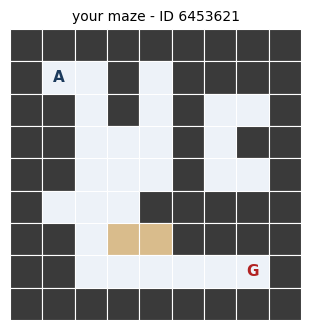

In [46]:
STUDENT_ID = "6453621"     # <-- your Panther ID, as a string, e.g. "6312345"

W = my_maze(STUDENT_ID)
print("mud (entry cost 6):", dict(sorted(W.mud.items())))
draw(W, title=f"your maze - ID {STUDENT_ID}")

---
# Part A — Same maze, a sense of direction

One maze. The driver from Homework 1, plus one number per state and two new
containers. You write the number, the changed driver, and the containers.

### A1 · The agent that already knew where the exit was

Homework 1 ended with a driver that never read `world.exit`. Hill climbing did
read it — at every square it stepped to the neighbour closest to the exit in
straight-line distance — and it still failed. Run it again on your maze.

reached the exit? False
stuck at         : (4, 4)


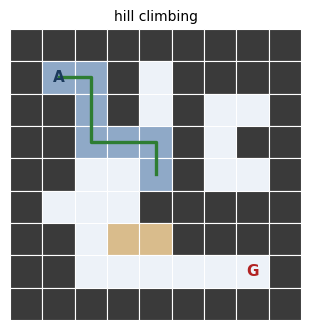

In [47]:
hc = hill_climbing(W)
print("reached the exit?", hc["reached_exit"])
print("stuck at         :", hc["stuck_at"])
draw(W, expanded=hc["visited"], path=hc["visited"], title="hill climbing")

**A1.1** Hill climbing turns the exit's location into one number per square
and acts on it; Homework 1's driver ignored the exit. This module combines the
two. In the driver this number is called `h`. Which of the three keys use it?
Then name two things the driver keeps that hill climbing had no equivalent of,
and say what each one prevents.

> _Your answer:_ The keys that use h are h (greedy best-first search) and g + h (A*). Uniform-cost search uses only g. Unlike hill climbing, these search methods keep a frontier of alternative paths, so they can try another route instead of getting stuck. They also track the best cost found for each state so they can use a cheaper route when one is discovered.


### A2 · The heuristic ★

`h(s)` estimates the cost still to come from `s` to the exit. On a grid with
four moves the standard choice is the **Manhattan distance**: the row gap plus
the column gap, walls ignored.

Write it. `world.exit` is the exit's `(row, column)`.

In [48]:
def manhattan(world, s):
    """Manhattan distance from s to the exit: row gap + column gap."""
    # YOUR CODE HERE
    exit_state = world.exit
    return abs(s[0] - exit_state[0]) + abs(s[1] - exit_state[1])

The cell below compares your `h` with the *true* cheapest cost from every free
square to the exit, on your maze with its mud. Run it.

Manhattan: 23 free squares - exact on 16, below the truth on 7, ABOVE the truth on 0


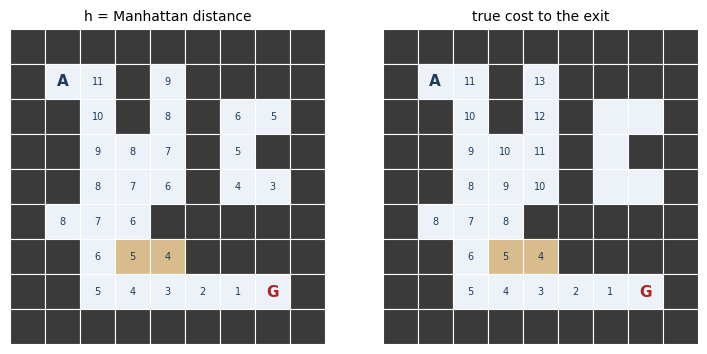

In [49]:
check_heuristic(W, manhattan, name="Manhattan")

truth = true_cost_to_exit(W)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.6))
draw(W, labels={s: manhattan(W, s) for s in W.free_cells()}, title="h = Manhattan distance", ax=axes[0])
draw(W, labels=truth, title="true cost to the exit", ax=axes[1])
plt.tight_layout()

**A2.1** On how many squares is your `h` exactly right, and on how many is it
below the truth? Explain, using the words *wall* and *mud*, why it can be below
the truth on a square but never above it.

> _Your answer:_ 'h' is exactly correct for 16 squares, it is below the truth for 7 squares. The 'h' value can never over-estimate the true cost because it would not be admissible otherwise, this would mean that it can no longer guarantee finding the minimum number of moves to reach the exit without taking into account the walls or mud. They may increase the actual cost greater than the estimate, but never lower.

**A2.2** The true cost on the right was computed by a search from the exit.
It is exact, so it would be the best possible heuristic. Why does A* not
simply use it?

> _Your answer:_ A* would need to run a search to calculate the true cheapest cost from every square before using the perfect heuristic. This means solving much of the maze in advance, which could take as much time as or more time than the search the heuristic was supposed to help.


### A3 · The driver, with a new push rule ★

The Homework 1 driver is given to you in Section 0 as `search_blind`. Copy its
shape, then make three changes:

1. Every node carries its estimate: with `g = node.g + cost`, create nodes as
   `Node(v, node, a, g, h(world, v))`, so the container can read `node.g`,
   `node.h` and `node.f`.
2. **The push rule changes.** Homework 1 pushed a state only when it was *not
   yet discovered*. Now push a state when it is **new, or when the new route
   to it is cheaper** than the cost recorded before. Keep a dictionary of the
   cheapest `g` recorded for each state.
3. **Out-of-date entries.** Because of rule 2, one state can have two entries
   in the frontier. When an entry pops for a state that was **already
   expanded**, skip it — it is out of date. Keep a set of expanded states.
   (Rule 2 is the one A5 checks. Rule 3 changes no expansion count or route
   cost in Part A; it stops wasted work, and it can change the peak frontier
   size — so keep it.)

Everything else stays: the goal test happens when a node is **popped**, and
`world.neighbours` already returns U, R, D, L order.

Return the goal `Node`, or `None` if the frontier empties.

In [50]:
def search(world, frontier, h):
    """The informed driver:  pop -> goal test -> expand -> push,
    with h on every node and the push rule 'new or cheaper'."""
    start = world.initial_state()
    start_node = Node(start, None, None, 0, h(world, start))
    frontier.push(start_node)

    best_g = {start: 0}
    expanded = set()

    while not frontier.is_empty():
        node = frontier.pop()

        # Skip out-of-date entries
        if node.state in expanded:
            continue

        expanded.add(node.state)

        if world.is_goal(node.state):
            return node

        for (a, v, cost) in world.neighbours(node.state):
            g = node.g + cost
            if v not in best_g or g < best_g[v]:
                best_g[v] = g
                frontier.push(Node(v, node, a, g, h(world, v)))

    return None

### A4 · Two more containers ★

`PriorityByG` (uniform-cost search) is given in Section 0. Write the other two.
Each class needs exactly two short methods, as in Homework 1. Use `heapq` with
`next(self._seq)` as the tie-breaker, so equal keys come out oldest-first.

* `PriorityByH` — smallest `node.h` first → greedy best-first search
* `PriorityByF` — smallest `node.g + node.h` first → A*

In [51]:
class PriorityByH(Frontier):
    """Greedy best-first: the node with the smallest h comes out next."""
    def _put(self, node):
         heapq.heappush(
              self._items,
               (node.h, next(self._seq), node)
        )
    def _take(self):
        return heapq.heappop(self._items)[2]


class PriorityByF(Frontier):
    """A*: the node with the smallest f = g + h comes out next."""
    def _put(self, node):
        heapq.heappush(
            self._items,
            (node.f, next(self._seq), node)
        )
    def _take(self):
       return heapq.heappop(self._items)[2]

### A5 · Check yourself against the lecture

The lecture ran greedy best-first search and A* on the 9×9 arena maze and
published the numbers. Your code should reproduce them exactly. The fifth line
runs A* on a second maze where the old push rule from Homework 1 returns a
route that is *not* the cheapest; only the new rule gets cost 17.

If a line does not match, the usual causes are the goal test at push instead
of pop, the wrong number in the key, a push rule that still says "not yet
discovered", or a priority queue that breaks ties the wrong way.

Fix your code until this cell prints **all five OK**. Do not edit the cell.

In [52]:
def _report(world, frontier, h):
    node = search(world, frontier, h)
    return {"pops": frontier.expansions, "peak": frontier.peak,
            "route_len": None if node is None else len(node.states()) - 1,
            "route_cost": None if node is None else node.g,
            "node": node}

_LECTURE = MazeWorld()                       # the arena maze, with its mud
_CHECK = MazeWorld(grid=CHECK_GRID, mud=CHECK_MUD)
_ok = True
for _name, _world, _F in (("greedy, no mud", _LECTURE.unit(), PriorityByH),
                          ("greedy, mud",    _LECTURE,        PriorityByH),
                          ("A*, mud",        _LECTURE,        PriorityByF),
                          ("UCS, mud",       _LECTURE,        PriorityByG),
                          ("A*, push rule",  _CHECK,          PriorityByF)):
    _r = _report(_world, _F(), manhattan)
    _want = LECTURE_TRUTH[_name]
    _bad = {k: (_r[k], v) for k, v in _want.items() if _r.get(k) != v}
    _ok &= not _bad
    print(f"{_name:15s} expanded={_r['pops']:3d} peak={_r['peak']:2d} "
          f"len={_r['route_len']} cost={_r['route_cost']}  "
          + ("OK" if not _bad else f"MISMATCH got/want {_bad}"))
print("\nall five OK" if _ok else "\nnot yet - keep fixing")

greedy, no mud  expanded= 13 peak= 6 len=12 cost=12  OK
greedy, mud     expanded= 13 peak= 6 len=12 cost=22  OK
A*, mud         expanded= 31 peak= 4 len=16 cost=16  OK
UCS, mud        expanded= 33 peak= 4 len=16 cost=16  OK
A*, push rule   expanded= 26 peak= 6 len=12 cost=17  OK

all five OK


### A6 · The comparison

Run all three keys on **your** maze and fill in the table from the output.
Blue squares were expanded; the green line is the route returned.

UCS     expanded= 22  peak frontier= 5  route length=12  route cost=12
        route: [(1, 1), (1, 2), (2, 2), (3, 2), (4, 2), (5, 2), (6, 2), (7, 2), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7)]
        mud on this route: []
greedy  expanded= 15  peak frontier= 6  route length=12  route cost=22
        route: [(1, 1), (1, 2), (2, 2), (3, 2), (3, 3), (4, 3), (5, 3), (6, 3), (6, 4), (7, 4), (7, 5), (7, 6), (7, 7)]
        mud on this route: [(6, 3), (6, 4)]
A*      expanded= 18  peak frontier= 5  route length=12  route cost=12
        route: [(1, 1), (1, 2), (2, 2), (3, 2), (4, 2), (5, 2), (6, 2), (7, 2), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7)]
        mud on this route: []

squares UCS expanded but A* did not (g = cheapest cost from the start):
   (1, 4): g =  7  h =  9  g + h = 16    (A*'s route costs 12)
   (2, 4): g =  6  h =  8  g + h = 14    (A*'s route costs 12)
   (5, 1): g =  6  h =  8  g + h = 14    (A*'s route costs 12)
   (6, 3): g = 12  h =  5  g + h = 17    (A*'s route costs 12

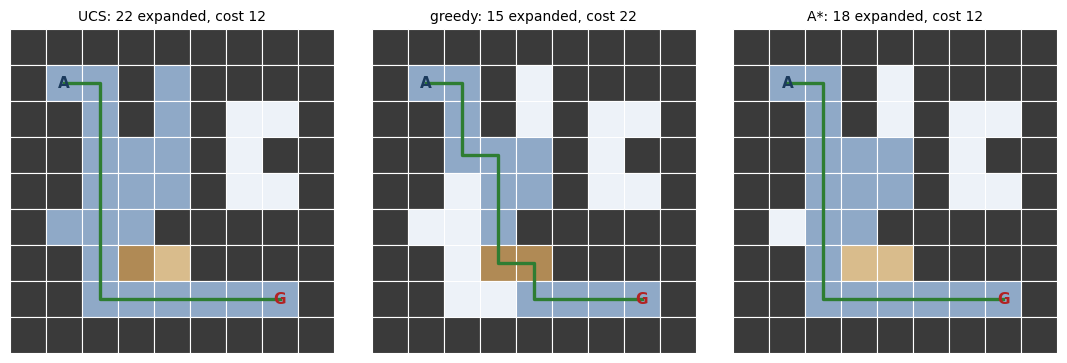

In [53]:
results = {}
for name, F in (("UCS", PriorityByG), ("greedy", PriorityByH), ("A*", PriorityByF)):
    f = F()
    node = search(W, f, manhattan)
    results[name] = {"pops": f.expansions, "peak": f.peak, "node": node,
                     "route_len": len(node.states()) - 1, "route_cost": node.g,
                     "expanded": f.expanded, "order": list(f.order), "g_at": dict(f.g_at)}
    r = results[name]
    print(f"{name:7s} expanded={r['pops']:3d}  peak frontier={r['peak']:2d}  "
          f"route length={r['route_len']:2d}  route cost={r['route_cost']}")
    print(f"        route: {node.states()}")
    print(f"        mud on this route: {sorted(set(node.states()) & set(W.mud))}")

print("\nsquares UCS expanded but A* did not (g = cheapest cost from the start):")
for s in sorted(results["UCS"]["expanded"] - results["A*"]["expanded"]):
    g, h = results["UCS"]["g_at"][s], manhattan(W, s)
    print(f"   {s}: g = {g:2d}  h = {h:2d}  g + h = {g + h:2d}    (A*'s route costs {results['A*']['route_cost']})")

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, name in zip(axes, ("UCS", "greedy", "A*")):
    r = results[name]
    draw(W, expanded=r["expanded"], path=r["node"].states(),
         title=f"{name}: {r['pops']} expanded, cost {r['route_cost']}", ax=ax)
plt.tight_layout()

Fill this in from your own output.

| key | algorithm | squares expanded | peak frontier | route length | route cost | cheapest? |
|---|---|---|---|---|---|---|
| `g` | uniform-cost search |22 | 5|12 |12 |yes |
| `h` | greedy best-first search | 15|6 | 12|22 | No|
| `g + h` | A* |18 |5 | 12|12 |yes |

**A6.1** Greedy best-first search expanded the fewest squares in your table
and returned the most expensive route. Give the coordinates of a mud square
that it walked through and uniform-cost search avoided, and explain in one
sentence why its key gives no warning that the square is expensive.

> _Your answer:_ Greedy search entered mud squares (6, 3) and (6, 4), while uniform-cost search avoided them. Greedy uses only h, the estimated distance to the exit, so it does not account for the extra cost of entering mud.


**A6.2** A* and uniform-cost search returned routes of the same cost. The
output lists the squares uniform-cost search expanded and A* did not, with
their `g + h`. Compare each `g + h` with the cost of the route A* returned.
Why does A* never need to pop those squares?

> _Your answer:_ A* never needs to pop those squares because it takes into account the actual move cost from the starting square and the expected value cost, meaning that the value of g + h are greater than or equal to the cost of the route A.

**A6.3** You changed two things between Homework 1 and now: the push rule, and
the key. Which change lets A* skip squares that uniform-cost search expands?
And which change protects the cheapest-route guarantee when a square is first
discovered by an expensive route — the case the fifth line of A5 tests? One
sentence each.

> _Your answer:_ Using g + h lets A* consider both the cost already paid and the estimated cost remaining, helping it avoid exploring routes that cannot beat the best route. Allowing a state to be pushed again when a cheaper route is found also helps preserve the guarantee of finding the cheapest route.

---
# Part B — Same driver, four heuristics

The driver and the container stop changing here: everything below is A*, with
`PriorityByF`. Only the heuristic changes. For each one you answer the same two
questions:

1. **Is it admissible** — does it ever report more than the true cost?
2. **What did the guarantee do** — is the route still the cheapest, and how
   many squares were expanded compared with Manhattan distance?

Each heuristic is written for you. You are not asked to design one until B5.

### B0 · The heuristic table

Fill one row per heuristic as you go through B1–B4. The Manhattan row comes
from A6.

| heuristic | admissible? | ≤ Manhattan everywhere? | squares expanded | route cost | cheapest? |
|---|---|---|---|---|---|
| Manhattan distance (A6) | yes | — |18 | 12| yes|
| `h = 0` (B1) |Yes | Yes| 22|12 |yes|
| Euclidean distance (B2) | yes| Yes|19 |12 |Yes|
| 3 × Manhattan (B3) |No |No | 15| 17|No |
| the true cost (B4) |Yes | No |13 |12 |yes |

### B1 · No estimate at all

`h(s) = 0` for every square: the key `g + h` is just `g`.

> _My prediction:_ compared with the uniform-cost row of A6, the number of
> squares expanded will stay the same and the route cost will stay the same, because when h=0, the A priority g+h, which is the same priority used by ucs search.

h = 0 :  expanded=22  route cost=12   (UCS in A6: expanded=22  route cost=12)
same squares, in the same order, as uniform-cost search? True


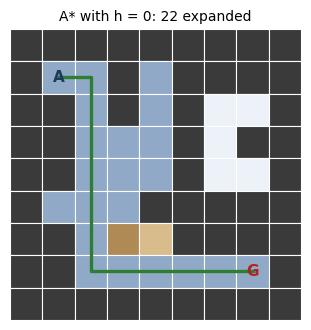

In [54]:
def zero(world, s):
    return 0

f = PriorityByF(); node = search(W, f, zero)
print(f"h = 0 :  expanded={f.expansions}  route cost={node.g}   "
      f"(UCS in A6: expanded={results['UCS']['pops']}  route cost={results['UCS']['route_cost']})")
print("same squares, in the same order, as uniform-cost search?",
      list(f.order) == results["UCS"]["order"])
draw(W, expanded=f.expanded, path=node.states(), title=f"A* with h = 0: {f.expansions} expanded")

**B1.1** The output confirms that A* with `h = 0` and uniform-cost search
expanded the same squares in the same order. Explain why this is guaranteed on
every maze, not a coincidence of yours.

> _Your answer:_ When h = 0, every node has f = g + 0 = g. This is the same priority used by uniform-cost search. Both containers break ties by insertion order, so they expand the same squares in the same order.


**B1.2** `h = 0` is admissible. So is `h = 0` a good heuristic? Say what
"admissible" guarantees and what it does not guarantee.

> _Your answer:_ The h = 0 heuristic is admissible because it never overestimates the remaining cost. A* can still guarantee the cheapest route, but this heuristic provides no information about which direction is closer to the goal. Therefore, it does not reduce the search work compared with uniform-cost search.

### B2 · The straight line

`h(s)` = the Euclidean (straight-line) distance from `s` to the exit — the same
number hill climbing used in A1.

> _My prediction:_ compared with Manhattan distance, the number of squares
> expanded will increase, because on a grid with four moves the straight line is less than or equal to the Manhattan distance meaning that the heuristic value would be less informed

In [55]:
def euclidean(world, s):
    return math.dist(s, world.exit)

check_heuristic(W, euclidean, name="Euclidean")
f = PriorityByF(); node = search(W, f, euclidean)
print(f"Euclidean :  expanded={f.expansions}  route cost={node.g}   "
      f"(Manhattan in A6: expanded={results['A*']['pops']}  route cost={results['A*']['route_cost']})")

Euclidean: 23 free squares - exact on 6, below the truth on 17, ABOVE the truth on 0
Euclidean :  expanded=19  route cost=12   (Manhattan in A6: expanded=18  route cost=12)


**B2.1** On a grid with four moves, the straight-line distance is never larger
than the Manhattan distance, so Manhattan distance is the sharper of the two.
The lecture's rule says: with the sharper heuristic, A* never expands *more*
squares — equal is allowed, and on a small maze equal is common. Is your count
consistent with the rule? And why did both runs still return the cheapest
route?

> _Your answer:_ Our count is consistent with the rule, Euclidean expanded 19 squares whereas Manhattan expanded 18 squares. In this case the Manhattan distance was the sharper heuristic, meaning that A* will not expand more squares with it. Both runs return 12 as the cheapest route, since they are both admissible, meaning the optimal route can be found using both methods.

### B3 · An exaggeration

`h(s)` = 3 × the Manhattan distance: the same direction as Manhattan distance,
three times as large.

> _My prediction:_ the route cost will higher than the cheapest route, and the number of squares expanded
> will fewer, because tripling Manhattan distance makes the search strongly favor squares that appear closer to the exit, even when reaching them involves an expensive route.

3 x Manhattan: 23 free squares - exact on 1, below the truth on 0, ABOVE the truth on 22  (worst: (1, 1), over by 24)
3 x Manhattan :  expanded=15  route cost=17   (cheapest, from A6: 12)
route: [(1, 1), (1, 2), (2, 2), (3, 2), (3, 3), (4, 3), (5, 3), (6, 3), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7)]
mud on this route: [(6, 3)]   (mud on the cheapest route: [])


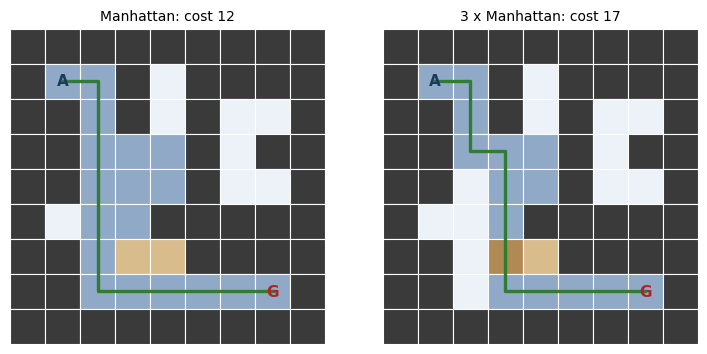

In [56]:
def triple(world, s):
    return 3 * manhattan(world, s)

check_heuristic(W, triple, name="3 x Manhattan")
f = PriorityByF(); node = search(W, f, triple)
print(f"3 x Manhattan :  expanded={f.expansions}  route cost={node.g}   "
      f"(cheapest, from A6: {results['UCS']['route_cost']})")
print(f"route: {node.states()}")
print(f"mud on this route: {sorted(set(node.states()) & set(W.mud))}   "
      f"(mud on the cheapest route: {sorted(set(results['A*']['node'].states()) & set(W.mud))})")

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.6))
draw(W, expanded=results["A*"]["expanded"], path=results["A*"]["node"].states(),
     title=f"Manhattan: cost {results['A*']['route_cost']}", ax=axes[0])
draw(W, expanded=f.expanded, path=node.states(), title=f"3 x Manhattan: cost {node.g}", ax=axes[1])
plt.tight_layout()

**B3.1** The route on the right is not the cheapest. Give the coordinates of a
mud square that 3 × Manhattan walked into and the cheapest route avoids. Then
explain, using the words *f* and *pop*, why the cheaper route around it was
never taken: what did the tripled `h` do to the key of the squares on that
detour?

> _Your answer:_ The tripled heuristic entered mud square (6, 3), while the cheapest route avoids mud. Tripling h makes the search favor squares that look closer to the exit, even if they lead to an expensive route. The search returned a route with cost 17 instead of the cheapest cost of 12.


**B3.2** The tripled heuristic also expanded *fewer* squares than Manhattan
distance. So it traded one thing for another. Name both, and say in which
situations a designer might accept that trade on purpose.

> _Your answer:_ The trade-off is that fewer squares are expanded, but the guarantee of finding the cheapest route is lost. This could be useful when finding a route quickly matters more than proving that it is the cheapest.

### B4 · The truth itself

`h(s)` = the true cheapest cost from `s` to the exit, computed for you by a
search from the exit. This is the perfect estimate — the one A2.2 asked about.

true cost: 23 free squares - exact on 23, below the truth on 0, ABOVE the truth on 0
true cost :  expanded=13  route length=12  route cost=12


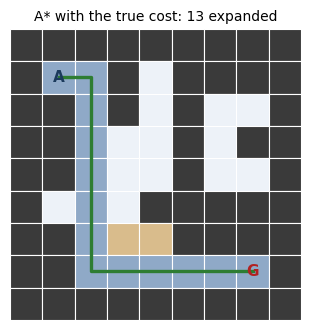

In [57]:
_truth = true_cost_to_exit(W)
def perfect(world, s):
    return _truth.get(s, math.inf)      # a square with no route to the exit: infinitely far

check_heuristic(W, perfect, name="true cost")
f = PriorityByF(); node = search(W, f, perfect)
print(f"true cost :  expanded={f.expansions}  route length={len(node.states()) - 1}  route cost={node.g}")
draw(W, expanded=f.expanded, path=node.states(), title=f"A* with the true cost: {f.expansions} expanded")

**B4.1** Compare the number of squares expanded with the route length (count
the start square). What does A* do with a perfect heuristic? And why can no
heuristic that still returns the *cheapest* route make A* expand fewer squares
than this on your maze?

> _Your answer:_ The true-cost heuristic expands 13 squares, which is the 12 moves on the optimal route plus the starting square. With a perfect heuristic, A* expands only the states on the optimal route in this maze. It must expand each state along the route to discover the next one and eventually reach the goal.


**B4.2** Order the five rows of the B0 table from fewest to most squares
expanded (ties are fine — write them as equal). Then say, in one sentence, what
the price of a sharper heuristic is — the price you pay *before* the search
starts.

> _Your answer:_ From fewest to most squares expanded, the order is true cost (13), 3 × Manhattan (15), Manhattan (18), Euclidean (19), and h = 0 (22). A more accurate heuristic can reduce search work, but calculating that heuristic may require extra computation.


### B5 · A new problem, on paper

No code for this one. This is the shape of the question the exam will ask.

> The **lecture maze** (the 9×9 arena maze of A5, start (1,1), exit (7,7),
> no mud) gains two **teleport pads**: P at (1,7) and Q at (7,6). Stepping onto
> P lands the robot on Q's square, and stepping onto Q lands it on P's square.
> The step costs 1 like any other move. Landing on a pad this way does not
> teleport the robot again. Everything else is unchanged: four moves, walls.

Write `md(a, b)` for the Manhattan distance between any two squares.

**B5.1** Is `md(s, exit)` still admissible in this maze? Answer yes or no and
give the reason. If it fails, give one square where it fails, with the value
of `md(s, exit)` and the true cost from that square.

> _Your answer:_ No it is not admissible in this maze, because if it steps on Q then it will get teleported away to P which is further away. The square it fails at is (6, 6), because following the Manhatten distance route could overestimate the cost, the addition of the teleporters could decrease the true cost to be smaller than the ordinary Manhattan distance.

**B5.2** Propose a heuristic that *is* admissible in this maze, as a formula
built from `md(s, exit)`, `md(s, P)`, `md(s, Q)`, `md(P, exit)` and
`md(Q, exit)`. Explain in one sentence why it never reports more than the
true cost.

> _Your answer:_ an admissible heuristic would be min{md(s, exit), md(s, P) + md(Q, exit), md(s, Q) + md(P, exit)}. It never reports more than the true cost because the Manhattan distance igores the walls, so by taking the minimum the heuristic value will always underestimate the true cost.

**B5.3** Manhattan distance, the straight-line distance and `h = 0` each came
from *relaxing* the problem: dropping a rule so that the relaxed problem is
easy to solve exactly. Which rule does your B5.2 heuristic drop? And which
rule does it respect that `md(s, exit)` ignores — and why is ignoring that
rule not a relaxation?

> _Your answer:_ The rule that B5.2 heuristic drops are the walls. The rule that it respects that md(s, exit) ignores is the teleporter, ignoring that rule is not relaxation because it removes the shortcut available in the real problem, and could increase the cost of the estimated route.

---
# Submission

**Before you export:** `Runtime → Restart session and run all`
(Colab) or `Kernel → Restart Kernel and Run All Cells` (Jupyter). Check that
A5 still prints **all five OK**.

Upload **both**:

1. `cai4002_hw2_<your Panther ID>.ipynb`
2. a PDF export of the same notebook

### What earns points

* **A2–A5** — your heuristic, driver and two containers reproduce the lecture's numbers (all five OK)
* **A1, A6** — the Part A written answers and the filled comparison table
* **B0** — the heuristic table
* **B1, B2, B3, B4** — the four heuristic runs and their written answers
* **B5** — the new problem, on paper
* **the three predictions** — credit for writing one, not for being right

**Due Sunday, October 11.** The exact time and the point values are on Canvas.